In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import psycopg2
import os


warnings.filterwarnings('ignore')

In [2]:
conn=psycopg2.connect(
    host="localhost",
    user='postgres',
    password='Pinku@2003#',
    dbname='olist',
    port=5432
)

In [3]:
df = pd.read_sql("SELECT * FROM order_analysis", conn)

In [4]:
df

,order_id,customer_state,purchase_ts,delivered_ts,estimated_ts,days_vs_estimate,is_late,review_score,order_value,freight,item_count
0,e481f51cbdc54678b7cc49136f2d6af7,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,-8,0,4.0,29.99,8.72,1
1,47770eb9100c2d0c44946d9cf07ec65d,GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,-18,0,5.0,159.90,19.22,1
2,949d5b44dbf5de918fe9c16f97b45f8a,RN,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,-13,0,5.0,45.00,27.20,1
3,a4591c265e18cb1dcee52889e2d8acc3,PR,2017-07-09 21:57:05,2017-07-26 10:57:55,2017-08-01,-6,0,4.0,147.90,27.36,1
4,76c6e866289321a7c93b82b54852dc33,RS,2017-01-23 18:29:09,2017-02-02 14:08:10,2017-03-06,-32,0,1.0,19.90,16.05,1
...,...,...,...,...,...,...,...,...,...,...,...
96465,b0f4af5c1b06e24fef510703bfe9f0a6,AL,2017-10-27 15:21:00,2017-11-10 17:57:22,2017-11-22,-12,0,5.0,142.50,21.80,1
96466,aa04ef5214580b06b10e2a378300db44,MG,2017-01-27 00:30:03,2017-02-07 13:15:25,2017-03-17,-38,0,5.0,370.00,19.43,1
96467,9c5dedf39a927c1b2549525ed64a053c,SP,2017-03-09 09:54:05,2017-03-17 15:08:01,2017-03-28,-11,0,5.0,72.00,13.08,1
96468,83c1379a015df1e13d02aae0204711ab,BA,2017-08-27 14:46:43,2017-09-21 11:24:17,2017-09-27,-6,0,5.0,205.99,65.02,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96470 entries, 0 to 96469
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          96470 non-null  str           
 1   customer_state    96470 non-null  str           
 2   purchase_ts       96470 non-null  datetime64[us]
 3   delivered_ts      96470 non-null  datetime64[us]
 4   estimated_ts      96470 non-null  datetime64[us]
 5   days_vs_estimate  96470 non-null  int64         
 6   is_late           96470 non-null  int64         
 7   review_score      95824 non-null  float64       
 8   order_value       96470 non-null  float64       
 9   freight           96470 non-null  float64       
 10  item_count        96470 non-null  int64         
dtypes: datetime64[us](3), float64(3), int64(3), str(2)
memory usage: 8.1 MB


In [6]:
df["is_late"].value_counts()

is_late
0    89936
1     6534
Name: count, dtype: int64

#### Chart 1, average review for on-time vs late orders.

In [7]:
notes_dir = "../notes" if os.path.basename(os.getcwd()) == "notebooks" else "notes"
os.makedirs(notes_dir, exist_ok=True)

In [8]:
avg = df.groupby("is_late")["review_score"].mean().round(2)
avg.index = ["On time", "Late"]

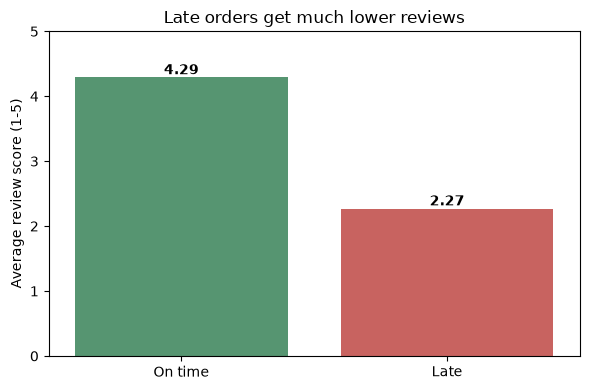

In [9]:
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=avg.index, y=avg.values, hue=avg.index,
                 palette=["#4C9F70", "#D9534F"], legend=False)
for i, v in enumerate(avg.values):
    ax.text(i, v + 0.05, str(v), ha="center", fontweight="bold")
plt.ylim(0, 5)
plt.ylabel("Average review score (1-5)")
plt.xlabel("")
plt.title("Late orders get much lower reviews")
plt.tight_layout()
plt.savefig(f"{notes_dir}/chart1_avg_review.png", dpi=150)
plt.show()

#### Chart 2: % of unhappy customers by how late the order was.

In [10]:
df["lateness"] = pd.cut(
    df["days_vs_estimate"],
    bins=[-float("inf"), 0, 3, 7, float("inf")],
    labels=["On time", "1-3 days late", "4-7 days late", "8+ days late"],
)

In [11]:
# Only orders that have a review; unhappy = 1 or 2 stars
reviewed = df.dropna(subset=["review_score"]).copy()

In [12]:
reviewed["unhappy"] = (reviewed["review_score"] <= 2).astype(int)

In [13]:
pct = (reviewed.groupby("lateness", observed=True)["unhappy"].mean() * 100).round(1)
print(pct)

lateness
On time           9.3
1-3 days late    32.1
4-7 days late    67.6
8+ days late     79.3
Name: unhappy, dtype: float64


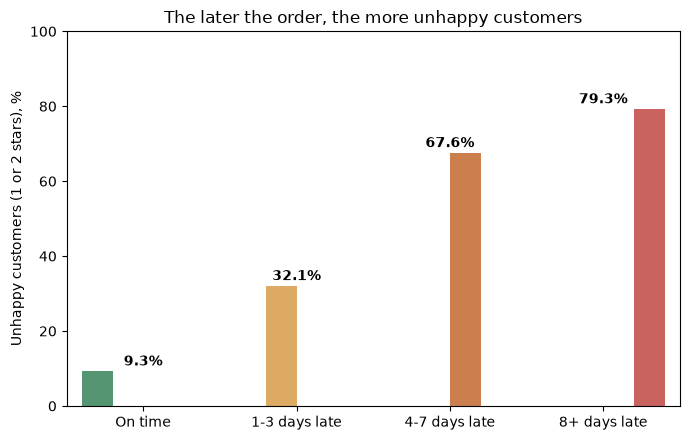

In [14]:
plt.figure(figsize=(7, 4.5))
ax = sns.barplot(x=pct.index, y=pct.values, hue=pct.index,
                 palette=["#4C9F70", "#F0AD4E", "#E07B39", "#D9534F"], legend=False)
for i, v in enumerate(pct.values):
    ax.text(i, v + 1.5, f"{v}%", ha="center", fontweight="bold")
plt.ylim(0, 100)
plt.ylabel("Unhappy customers (1 or 2 stars), %")
plt.xlabel("")
plt.title("The later the order, the more unhappy customers")
plt.tight_layout()
plt.savefig(f"{notes_dir}/chart2_unhappy_by_lateness.png", dpi=150)
plt.show()

#### The test, to check the review gap is real..

In [15]:
from scipy import stats

In [16]:
ontime = df.loc[df["is_late"] == 0, "review_score"].dropna()

In [17]:
late = df.loc[df["is_late"] == 1, "review_score"].dropna()

In [18]:
print("On time: orders =", len(ontime), "| average =", round(ontime.mean(), 2))
print("Late:    orders =", len(late), "| average =", round(late.mean(), 2))
print("Gap in stars:", round(ontime.mean() - late.mean(), 2))


On time: orders = 89443 | average = 4.29
Late:    orders = 6381 | average = 2.27
Gap in stars: 2.02


In [19]:
stat, p = stats.mannwhitneyu(ontime, late, alternative="two-sided")
print("p-value:", p)

p-value: 0.0


#### 1.The p-value is the chance of seeing a gap this big if lateness had no effect. Below 0.05 means the gap is real, not luck.
#### 2.The p-value alone is not enough. With about 96,000 orders, even a tiny gap gives a tiny p-value. The size of the gap, about 2 stars, is what matters.
#### 3.What it does not prove: that lateness alone causes the low scores. It shows a strong link.